In [ ]:
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = next(
    (
        folder
        for folder in (current_dir, *current_dir.parents)
        if (folder / "pyproject.toml").is_file()
        and (folder / "notebooks" / "work24_sample.ipynb").is_file()
    ),
    None,
)

if project_root is None:
    raise RuntimeError("SkillBridge 폴더나 그 하위 폴더에서 노트북 커널을 시작해 주세요.")
env_path = project_root / ".env"

if not env_path.is_file():
    raise FileNotFoundError(f".env 파일을 찾지 못했어요. 확인할 위치: {env_path}")

api_key = ""
for line in env_path.read_text(encoding="utf-8-sig").splitlines():
    name, separator, value = line.partition("=")
    if separator and name.strip() == "WORK24_API_KEY":
        api_key = value.strip()
        break

if not api_key:
    raise ValueError(".env에 WORK24_API_KEY=발급받은_인증키 형식으로 입력해 주세요.")

print("인증키를 읽었어요.")

In [20]:
from urllib.error import HTTPError, URLError
from urllib.parse import urlencode
from urllib.request import urlopen
from xml.etree import ElementTree

api_base = "https://www.work24.go.kr/cm/openApi/call/wk"


def fetch_xml(endpoint, params):
    query = urlencode({"authKey": api_key, "returnType": "XML", **params})

    try:
        with urlopen(f"{endpoint}?{query}", timeout=15) as response:
            raw_xml = response.read()
    except HTTPError as error:
        raise RuntimeError(f"고용24 요청 실패 (HTTP {error.code})") from None
    except (URLError, TimeoutError):
        raise RuntimeError("고용24 서버에 연결하지 못했어요.") from None

    try:
        return raw_xml, ElementTree.fromstring(raw_xml)
    except ElementTree.ParseError:
        raise RuntimeError("고용24 응답을 XML로 읽지 못했어요.") from None


page_size = 10
max_pages = 3
posts = []
seen_ids = set()

for page in range(1, max_pages + 1):
    _, list_root = fetch_xml(
        f"{api_base}/callOpenApiSvcInfo210L21.do",
        {
            "callTp": "L",
            "startPage": page,
            "display": page_size,
            "jobsCd": "024",
        },
    )

    if list_root.tag != "dhsOpenEmpInfoList":
        raise RuntimeError(f"{page}페이지에서 공채속보 목록을 받지 못했어요.")

    total = int(list_root.findtext("total", "0"))
    if page == 1:
        print(f"소프트웨어 직종 전체 공고 수: {total}건")

    page_posts = list_root.findall("dhsOpenEmpInfo")

    for post in page_posts:
        number = post.findtext("empSeqno", "").strip()
        if number and number not in seen_ids:
            seen_ids.add(number)
            posts.append(post)

    if not page_posts or page * page_size >= total:
        break

print(f"이번에 가져온 공고: {len(posts)}건 (중복 제외)")

for post in posts:
    number = post.findtext("empSeqno", "").strip()
    company = post.findtext("empBusiNm", "")
    title = post.findtext("empWantedTitle", "")
    print(f"{number} | {company} | {title}")

소프트웨어 직종 전체 공고 수: 24건
이번에 가져온 공고: 24건 (중복 제외)
185571 | 한국보건의료정보원 | 2026년 6차 직원채용
185569 | 케이디비생명보험 | 2026년 4분기 경력직 채용
185562 | 넷마블네오 | 2026 AI 인턴십 채용
185557 | 에스케이시그넷 | 전기차 충전기 SW/FW 검증 및 시험 자동화 엔지니어
185524 | 우리금융캐피탈 | 2027년 정규직 신입사원 채용 공고
185464 | 캐논코리아 | 2026년 11월 경력사원(계약직) 채용
185408 | 안랩 | 2026 신입/경력 공개채용 (사업/STAFF)
185407 | 안랩 | 2026 신입/경력 공개채용 (연구소)_Web개발
185406 | 안랩 | 2026 신입/경력 공개채용 (연구소)
185402 | 펄어비스 | [겨울 인턴십] 엔지니어링_게임 개발 엔지니어
185401 | 펄어비스 | [겨울 인턴십] 엔지니어링_모바일플랫폼
185400 | 펄어비스 | [겨울 인턴십] 엔지니어링_빌드시스템개발
185399 | 펄어비스 | [겨울 인턴십] 엔지니어링_DBA
185398 | 펄어비스 | [겨울 인턴십] 엔지니어링_데이터분석
185397 | 펄어비스 | [겨울 인턴십] 엔지니어링_웹개발(백엔드)
185392 | 펄어비스 | [겨울 인턴십] 사업/서비스_서비스디자인(웹기획)
185246 | 엘엑스세미콘 | 2026년 11월 경력사원 채용 (서울/대전)
185243 | 앰코테크놀로지코리아 | [신입] 고객만족팀 업무 자동화 모집 (인천 송도)
185206 | 에어퍼스트 | 2027년 동계 각 부문 인턴 채용공고
184878 | 삼성메디슨 | 2026년 하반기 3급 신입사원 채용
184650 | 아머스포츠코리아 | 웹 기획자 경력직 채용
184648 | 한국기계연구원 | 2026년도 제3회 신입직원 공개채용
184156 | 더존비즈온 | [AI 개발] AI 에이전트 개발자 경력 추가 채용
182207 | 안진회계법인 | 경영지원부문 IT AI 엔지니어

In [21]:
raw_dir = project_root / "data" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)

roles = []
failed_ids = []

for post in posts:
    number = post.findtext("empSeqno", "").strip()

    try:
        raw_xml, detail = fetch_xml(
            f"{api_base}/callOpenApiSvcInfo210D21.do",
            {"callTp": "D", "empSeqno": number},
        )

        if (
            detail.tag != "dhsOpenEmpInfoDetailRoot"
            or detail.findtext("empSeqno", "").strip() != number
        ):
            raise RuntimeError("요청한 공고의 상세 응답을 받지 못했어요.")
    except RuntimeError:
        failed_ids.append(number)
        continue

    (raw_dir / f"work24_sample_{number}.xml").write_bytes(raw_xml)

    for role in detail.findall("./empRecrList/empRecrListInfo"):
        roles.append({
            "공고번호": number,
            "회사명": detail.findtext("empBusiNm", ""),
            "모집직무": role.findtext("empRecrNm", ""),
            "직무내용": role.findtext("jobCont", ""),
            "자격요건": role.findtext("sptCertEtc", ""),
        })

print(f"상세 조회 성공 {len(posts) - len(failed_ids)}건 / 요청 {len(posts)}건")
print(f"확인할 모집 직무 {len(roles)}개")
if failed_ids:
    print("조회 실패 공고 번호", ", ".join(failed_ids))

상세 조회 성공 24건 / 요청 24건
확인할 모집 직무 39개


In [22]:
import csv
from xml.etree import ElementTree as ET

raw_dir = project_root / "data" / "raw"
processed_dir = project_root / "data" / "processed"
xml_files = sorted(raw_dir.glob("work24_sample_*.xml"))

if not xml_files:
    raise FileNotFoundError(f"원본 XML을 찾지 못했어요. 확인할 폴더: {raw_dir}")

rows = []

for xml_file in xml_files:
    detail = ET.parse(xml_file).getroot()

    for role in detail.findall("./empRecrList/empRecrListInfo"):
        rows.append({
            "공고번호": detail.findtext("empSeqno", "").strip(),
            "회사명": detail.findtext("empBusiNm", "").strip(),
            "공고제목": detail.findtext("empWantedTitle", "").strip(),
            "모집직무": role.findtext("empRecrNm", "").strip(),
            "경력조건": role.findtext("empWantedCareerNm", "").strip(),
            "직무내용": role.findtext("jobCont", "").strip(),
            "자격요건": role.findtext("sptCertEtc", "").strip(),
            "공고URL": detail.findtext("empWantedHomepgDetail", "").strip(),
        })

if not rows:
    raise ValueError("XML에서 모집 직무를 찾지 못했어요.")

processed_dir.mkdir(parents=True, exist_ok=True)
csv_path = processed_dir / "work24_sample_roles.csv"

with csv_path.open("w", encoding="utf-8-sig", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)

print(f"읽은 공고 XML {len(xml_files)}건")
print(f"저장한 모집 직무 {len(rows)}행")
print(csv_path.relative_to(project_root))

읽은 공고 XML 24건
저장한 모집 직무 39행
data\processed\work24_sample_roles.csv


In [26]:
# 개발 관련으로 분류한 직무와 본문에서 확인한 기술명을 기록한다.
# []는 개발 관련 직무이지만 구체적인 기술명을 확인하지 못한 경우다.
import csv

csv_path = project_root / "data" / "processed" / "work24_sample_roles.csv"

with csv_path.open(encoding="utf-8-sig", newline="") as file:
    sample_rows = list(csv.DictReader(file))
    
reviewed_roles = {
    ("182207", "경영지원부문 IT AI 엔지니어"): ["Gemini", "AWS", "GCP", "Azure"],
    ("184156", "AI 에이전트 개발"): ["GPT", "Claude", "Python", "Linux"],
    ("184878", "SW개발"): [],
    ("184878", "영상개발"): [],
    ("185243", "업무 자동화(고객만족팀)"): ["Python", "Pandas", "Excel"],
    ("185397", "엔지니어링_웹개발(백엔드)"): [],
    ("185398", "엔지니어링_데이터분석"): ["SQL", "Python"],
    ("185399", "엔지니어링_DBA"): ["MS SQL Server", "SQL"],
    ("185400", "엔지니어링_빌드시스템개발"): [
        "C", "C++", "Python", "JavaScript", "TypeScript",
    ],
    ("185401", "엔지니어링_모바일플랫폼"): ["Android", "iOS", "React Native"],
    ("185402", "엔지니어링_게임 개발 엔지니어"): ["C++"],
    ("185406", "[SW 개발] OS기반 SW개발"): ["Windows", "Linux", "macOS"],
    ("185406", "[SW 개발] Web 개발"): [],
    ("185406", "[AI/ML] AI/ML 개발"): [],
    ("185406", "[엔지니어] DevOps"): [],
    ("185406", "[엔지니어] QA"): [],
    ("185407", "[SW 개발] Web 개발"): [],
    ("185464", "연구개발(S/W)"): ["Angular", "TypeScript"],
    ("185524", "디지털/IT"): [],
    ("185557", "[Tech R&D] SW 개발"): [],
    ("185569", "[대리~ 과장] 인터넷/모바일창구 운영"): [],
}

sample_keys = {
    (row["공고번호"].strip(), row["모집직무"].strip())
    for row in sample_rows
}
missing_keys = reviewed_roles.keys() - sample_keys

if len(sample_rows) != 39 or missing_keys:
    raise ValueError("검토에 사용한 CSV와 달라요. 공고와 모집직무를 다시 확인해 주세요.")

unique_roles = {}

for row in sample_rows:
    posting_id = row["공고번호"].strip()
    role_name = row["모집직무"].strip()
    review_key = (posting_id, role_name)

    if review_key not in reviewed_roles:
        continue

    # 채용 URL, 직무명, 직무내용이 같으면 같은 직무로 센다.
    duplicate_key = (
        row["공고URL"].strip() or posting_id,
        role_name,
        " ".join(row["직무내용"].split()),
    )
    unique_roles.setdefault(duplicate_key, set()).update(reviewed_roles[review_key])

posting_count = len({row["공고번호"].strip() for row in sample_rows})
role_count = len(unique_roles)
with_skills = sum(bool(skills) for skills in unique_roles.values())
skill_rate = with_skills / role_count if role_count else 0

print(f"수집한 공고: {posting_count}건")
print(f"검토한 모집 직무: {len(sample_rows)}행")
print(f"개발 관련 직무: {role_count}개 (중복 제외)")
print(f"구체적인 기술명이 나온 개발 관련 직무: {with_skills}개 ({skill_rate:.0%})")

수집한 공고: 24건
검토한 모집 직무: 39행
개발 관련 직무: 20개 (중복 제외)
구체적인 기술명이 나온 개발 관련 직무: 10개 (50%)


In [27]:
summary_path = project_root / "data" / "processed" / "work24_sample_summary.csv"

with summary_path.open("w", encoding="utf-8-sig", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["항목", "값"])
    writer.writerows([
        ["수집한 공고 수", posting_count],
        ["검토한 모집 직무 행 수", len(sample_rows)],
        ["개발 관련 직무 수 (중복 제외)", role_count],
        ["구체적인 기술명이 확인된 개발 관련 직무 수", with_skills],
        ["기술명 확인 비율", f"{skill_rate:.1%}"],
    ])

print("집계 저장", summary_path.relative_to(project_root))

집계 저장 data\processed\work24_sample_summary.csv


In [28]:
development_roles = {}

for row in sample_rows:
    posting_id = row["공고번호"].strip()
    role_name = row["모집직무"].strip()

    if (posting_id, role_name) not in reviewed_roles:
        continue

    # 마지막 집계 셀과 같은 기준으로 중복을 합친다.
    role_key = (
        row["공고URL"].strip() or posting_id,
        role_name,
        " ".join(row["직무내용"].split()),
    )

    record = development_roles.setdefault(role_key, {
        "공고번호": set(),
        "회사명": row["회사명"],
        "모집직무": role_name,
        "경력조건": row["경력조건"],
        "직무내용": row["직무내용"],
        "자격요건": row["자격요건"],
        "공고URL": row["공고URL"],
    })
    record["공고번호"].add(posting_id)

export_rows = []

for role_key, record in development_roles.items():
    skills = sorted(unique_roles[role_key], key=str.casefold)
    export_rows.append({
        **record,
        "공고번호": ", ".join(sorted(record["공고번호"])),
        "기술명 확인 여부": "확인" if skills else "미확인",
        "확인된 기술명": ", ".join(skills),
    })

output_path = (
    project_root / "data" / "processed" / "work24_sample_development_roles.csv"
)

with output_path.open("w", encoding="utf-8-sig", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(export_rows[0]))
    writer.writeheader()
    writer.writerows(export_rows)

print(f"개발 관련 직무 {len(export_rows)}행 저장")
print(f"기술명이 확인된 직무 {sum(bool(row['확인된 기술명']) for row in export_rows)}행")
print(output_path.relative_to(project_root))

개발 관련 직무 20행 저장
기술명이 확인된 직무 10행
data\processed\work24_sample_development_roles.csv


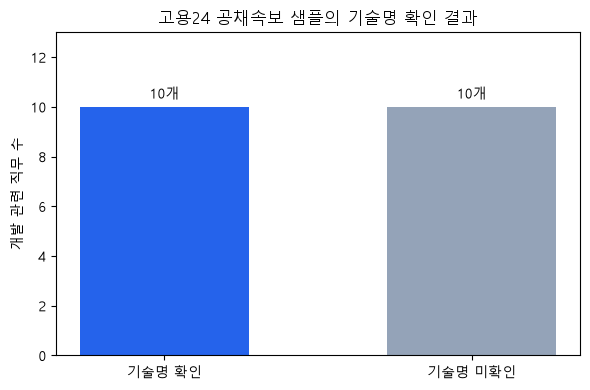

In [29]:
import matplotlib.pyplot as plt

# Windows에서 한글이 깨지지 않도록 글꼴을 설정한다.
plt.rcParams["font.family"] = "Malgun Gothic"

labels = ["기술명 확인", "기술명 미확인"]
counts = [with_skills, role_count - with_skills]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, counts, color=["#2563EB", "#94A3B8"], width=0.55)

ax.bar_label(bars, labels=[f"{count}개" for count in counts], padding=4)
ax.set_title("고용24 공채속보 샘플의 기술명 확인 결과")
ax.set_ylabel("개발 관련 직무 수")
ax.set_ylim(0, max(counts) + 3)

fig.tight_layout()
plt.show()

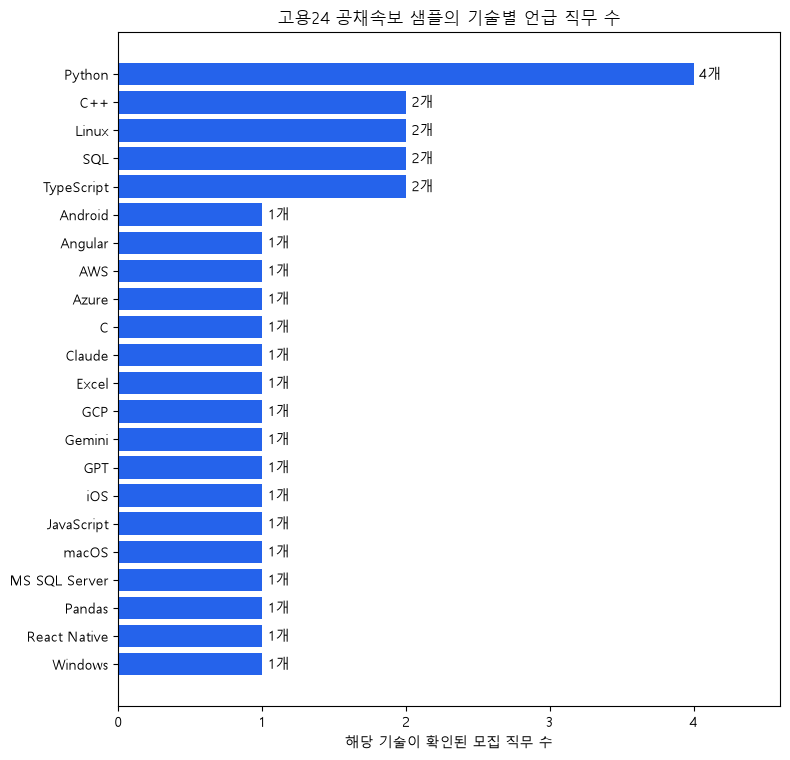

In [30]:
import csv
from collections import Counter

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

csv_path = (
    project_root / "data" / "processed" / "work24_sample_development_roles.csv"
)
skill_counts = Counter()

with csv_path.open(encoding="utf-8-sig", newline="") as file:
    for row in csv.DictReader(file):
        skills = {
            skill.strip()
            for skill in row["확인된 기술명"].split(",")
            if skill.strip()
        }
        skill_counts.update(skills)

if not skill_counts:
    raise ValueError("상세 CSV에서 확인된 기술명을 찾지 못했어요.")

ranked_skills = sorted(
    skill_counts.items(),
    key=lambda item: (-item[1], item[0].casefold()),
)
labels, counts = zip(*ranked_skills)

with plt.rc_context({"font.family": "Malgun Gothic"}):
    fig, ax = plt.subplots(figsize=(8, max(5, len(labels) * 0.35)))
    bars = ax.barh(labels, counts, color="#2563EB")

    ax.invert_yaxis()
    ax.bar_label(bars, labels=[f"{count}개" for count in counts], padding=4)
    ax.set_title("고용24 공채속보 샘플의 기술별 언급 직무 수")
    ax.set_xlabel("해당 기술이 확인된 모집 직무 수")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlim(0, max(counts) + 0.6)

    fig.tight_layout()
    plt.show()